# 03. モデリング：テキスト埋め込みとクラスタリング

## 概要
02_eda.ipynbで確定した前処理方針をもとに、
テキストの埋め込みとクラスタリングを実施する。

## 分析アプローチ
まず軽量なベースラインモデルで分析を行い、
結果を評価しながら最適なモデルを選定する。

## 入力
- `data/speeches_raw.csv`

## 出力
## 出力
- `data/embeddings_round1.npy`
- `data/embeddings_round2.npy`
- `data/embeddings_round3.npy`
- `data/embeddings_round4.npy`
- `data/embeddings_round5.npy`
- `data/embeddings_round6.npy`
- `data/speeches_clustered.csv` - 最終採用モデル（Round5）のクラスタリング結果

In [4]:
# ============================================================
# ライブラリのインポートとデータ読み込み
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize
import hdbscan
import umap
import os

# 日本語フォント設定
font_path = "/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/japanize_matplotlib/fonts/ipaexg.ttf"
fm.fontManager.addfont(font_path)
sns.set_style("whitegrid")
plt.rcParams["font.family"] = "IPAexGothic"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (12, 6)

# データ読み込み
df = pd.read_csv("../data/speeches_raw.csv")

# 「公平」「包括」を除外
df = df[~df["keyword"].str.split("|").str[0].isin(["公平", "包括"])]
df = df.reset_index(drop=True)

print(f"分析対象データ数: {len(df)}件")

分析対象データ数: 6301件


## 1. 前処理
発言テキストのクリーニングを行う。
- 発言者名の除去（「○○君」「○委員長」など）
- 改行・空白の正規化
- 5,000文字以上の発言は冒頭1,000文字に切り詰める

In [5]:
# ============================================================
# テキストの前処理
# ============================================================
import re

def clean_text(text):
    """
    発言テキストをクリーニングする関数
    
    処理内容：
    1. 発言者名を除去（例：「○山田太郎君　」）
    2. 改行・空白を正規化
    3. 5,000文字以上は冒頭1,000文字に切り詰め
    """
    # 発言者名を除去（○で始まり全角スペースで終わるパターン）
    text = re.sub(r'○[^　]+　', '', text)
    
    # 改行・連続空白を半角スペースに統一
    text = re.sub(r'[\r\n\s]+', ' ', text)
    
    # 前後の空白を除去
    text = text.strip()
    
    # 5,000文字以上は冒頭1,000文字に切り詰め
    if len(text) > 5000:
        text = text[:1000]
    
    return text

# 前処理を適用
df["speech_clean"] = df["speech"].apply(clean_text)

# 確認
print("=== 前処理前 ===")
print(df["speech"].iloc[0][:200])
print("\n=== 前処理後 ===")
print(df["speech_clean"].iloc[0][:200])
print(f"\n前処理後の平均文字数: {df['speech_clean'].str.len().mean():.0f}文字")

=== 前処理前 ===
○あかま委員長　これより会議を開きます。
　国土交通行政の基本施策に関する件について調査を進めます。
　この際、お諮りいたします。
　本件調査のため、本日、参考人として中日本高速道路株式会社代表取締役社長宮池克人君の出席を求め、意見を聴取することとし、また、政府参考人として国土交通省総合政策局長石田優君、不動産・建設経済局長青木由行君、水管理・国土保全局長井上智夫君、道路局長吉岡幹夫君、住宅

=== 前処理後 ===
これより会議を開きます。 国土交通行政の基本施策に関する件について調査を進めます。 この際、お諮りいたします。 本件調査のため、本日、参考人として中日本高速道路株式会社代表取締役社長宮池克人君の出席を求め、意見を聴取することとし、また、政府参考人として国土交通省総合政策局長石田優君、不動産・建設経済局長青木由行君、水管理・国土保全局長井上智夫君、道路局長吉岡幹夫君、住宅局長和田信貴君、鉄道局長上原

前処理後の平均文字数: 811文字


## 2. Round1：ベースラインモデル
軽量な多言語モデル（MiniLM-L12-v2）でテキストを埋め込み、
K-Meansでクラスタリングを行う。

段階的に試行錯誤していく。

In [4]:
# ============================================================
# Round1：埋め込み（MiniLM-L12-v2）
# 軽量な多言語モデルでベースラインを構築する
# ============================================================
from sentence_transformers import SentenceTransformer

print("モデルをロード中...")
model_r1 = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

print("埋め込みを計算中...（数分かかります）")
embeddings_r1 = model_r1.encode(
    df["speech_clean"].tolist(),
    batch_size=64,
    show_progress_bar=True
)

# 埋め込みを保存
np.save("../data/embeddings_round1.npy", embeddings_r1)
print(f"保存完了: ../data/embeddings_round1.npy")
print(f"埋め込みの形状: {embeddings_r1.shape}")

モデルをロード中...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

埋め込みを計算中...（数分かかります）


Batches:   0%|          | 0/99 [00:00<?, ?it/s]

保存完了: ../data/embeddings_round1.npy
埋め込みの形状: (6301, 384)


### Round1：K-meansクラスタリング
埋め込みベクトルをK-Meansでクラスタリングする。
最適なクラスタ数をエルボー法とシルエットスコアで決定する。

クラスタ数を探索中...
k=2: シルエットスコア=0.0563
k=3: シルエットスコア=0.0706
k=4: シルエットスコア=0.0760
k=5: シルエットスコア=0.0803
k=6: シルエットスコア=0.0791
k=7: シルエットスコア=0.0823
k=8: シルエットスコア=0.0810
k=9: シルエットスコア=0.0802
k=10: シルエットスコア=0.0760
k=11: シルエットスコア=0.0764
k=12: シルエットスコア=0.0766
k=13: シルエットスコア=0.0721
k=14: シルエットスコア=0.0616


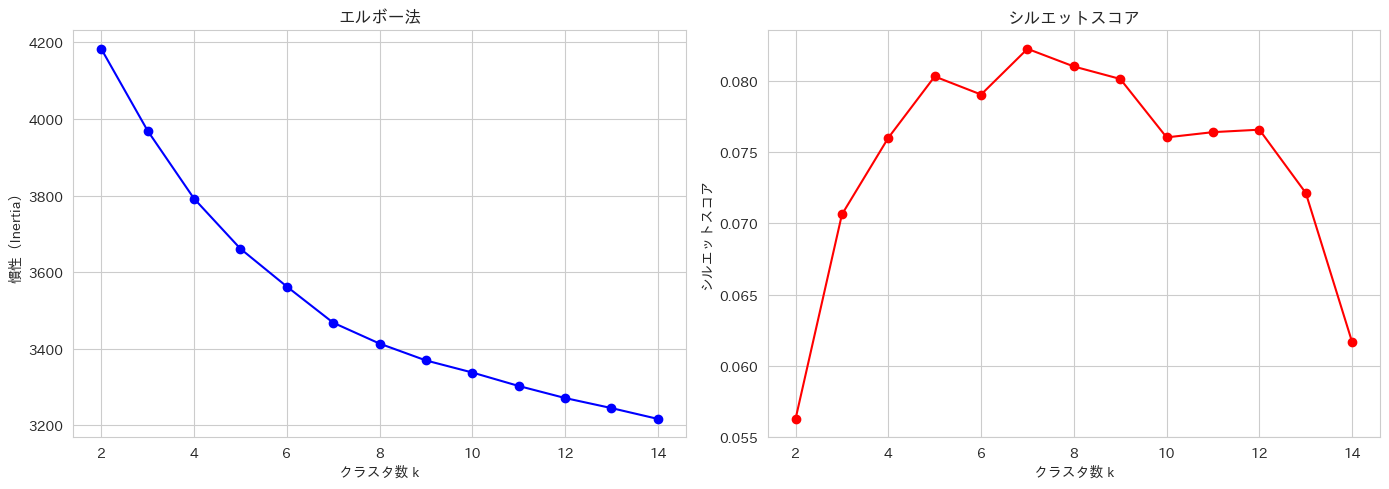

保存完了: ../data/round1_kmeans_search.png


In [5]:
# ============================================================
# Round1：最適クラスタ数の探索（エルボー法・シルエットスコア）
# ============================================================
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 正規化
embeddings_r1_norm = normalize(embeddings_r1)

inertias = []
silhouette_scores = []
K_range = range(2, 15)

print("クラスタ数を探索中...")
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(embeddings_r1_norm)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(embeddings_r1_norm, labels, sample_size=1000, random_state=42))
    print(f"k={k}: シルエットスコア={silhouette_scores[-1]:.4f}")

# 可視化
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias, "bo-")
axes[0].set_title("エルボー法")
axes[0].set_xlabel("クラスタ数 k")
axes[0].set_ylabel("慣性（Inertia）")

axes[1].plot(K_range, silhouette_scores, "ro-")
axes[1].set_title("シルエットスコア")
axes[1].set_xlabel("クラスタ数 k")
axes[1].set_ylabel("シルエットスコア")

plt.tight_layout()
plt.savefig("../data/round1_kmeans_search.png", dpi=150, bbox_inches="tight")
plt.show()
print("保存完了: ../data/round1_kmeans_search.png")

### Round1の結果と考察
- エルボー法では明確な肘(急激に下がりが緩やかになる)が見られず、データが綺麗に分離していない可能性
- シルエットスコア(1に近いほど良い)はk=7で最大（0.0823）だが全体的に低い（0.06〜0.08）
- MiniLMは軽量モデルのため日本語の意味捕捉が不十分な可能性がある
- → より高精度な埋め込みモデルへの変更を検討する

### Round1：k=7でクラスタリング実行
シルエットスコアが最大となったk=7でクラスタリングを実行する。

In [6]:
# ============================================================
# Round1：k=7でK-Meansクラスタリングを実行
# ============================================================

# k=7でクラスタリング
kmeans_r1 = KMeans(n_clusters=7, random_state=42, n_init=10)
df["cluster_r1"] = kmeans_r1.fit_predict(embeddings_r1_norm)

# クラスタ別件数を確認
print("=== Round1 クラスタ別件数 ===")
print(df["cluster_r1"].value_counts().sort_index())
print(f"\nシルエットスコア: {silhouette_score(embeddings_r1_norm, df['cluster_r1'], sample_size=1000, random_state=42):.4f}")

=== Round1 クラスタ別件数 ===
cluster_r1
0     825
1    1189
2    1021
3    1086
4     286
5    1212
6     682
Name: count, dtype: int64

シルエットスコア: 0.0823


### Round1 クラスタリング結果
| クラスタ | 件数 |
|---------|------|
| 0 | 825 |
| 1 | 1,189 |
| 2 | 1,021 |
| 3 | 1,086 |
| 4 | 286 |
| 5 | 1,212 |
| 6 | 682 |

- シルエットスコア: 0.0823
- クラスタ4が286件と突出して小さい → 少数派グループの可能性
- ただしK-Meansは球状クラスタを前提とするため、不規則な形状の少数派グループを正確に捉えられない可能性がある
- → Round2でより高精度な埋め込みモデルを試す

## 3. Round2：埋め込みモデルの改善
Round1のシルエットスコアが低かったため、より高精度な多言語モデル
（mpnet-base-v2）に変更してクラスタリングを再実行する。

In [7]:
# ============================================================
# Round2：埋め込み（paraphrase-multilingual-mpnet-base-v2）
# MiniLMより高精度な多言語モデルに変更する
# ============================================================

print("モデルをロード中...")
model_r2 = SentenceTransformer("paraphrase-multilingual-mpnet-base-v2")

print("埋め込みを計算中...（数分かかります）")
embeddings_r2 = model_r2.encode(
    df["speech_clean"].tolist(),
    batch_size=32,
    show_progress_bar=True
)

# 埋め込みを保存
np.save("../data/embeddings_round2.npy", embeddings_r2)
print(f"保存完了: ../data/embeddings_round2.npy")
print(f"埋め込みの形状: {embeddings_r2.shape}")

モデルをロード中...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

埋め込みを計算中...（数分かかります）


Batches:   0%|          | 0/197 [00:00<?, ?it/s]

保存完了: ../data/embeddings_round2.npy
埋め込みの形状: (6301, 768)


### Round2：K-Meansクラスタリング
Round1と同様にエルボー法とシルエットスコアで最適クラスタ数を探索する。

クラスタ数を探索中...
k=2: シルエットスコア=0.0610
k=3: シルエットスコア=0.0741
k=4: シルエットスコア=0.0856
k=5: シルエットスコア=0.0888
k=6: シルエットスコア=0.0843
k=7: シルエットスコア=0.0902
k=8: シルエットスコア=0.0920
k=9: シルエットスコア=0.0909
k=10: シルエットスコア=0.0886
k=11: シルエットスコア=0.0880
k=12: シルエットスコア=0.0768
k=13: シルエットスコア=0.0711
k=14: シルエットスコア=0.0724


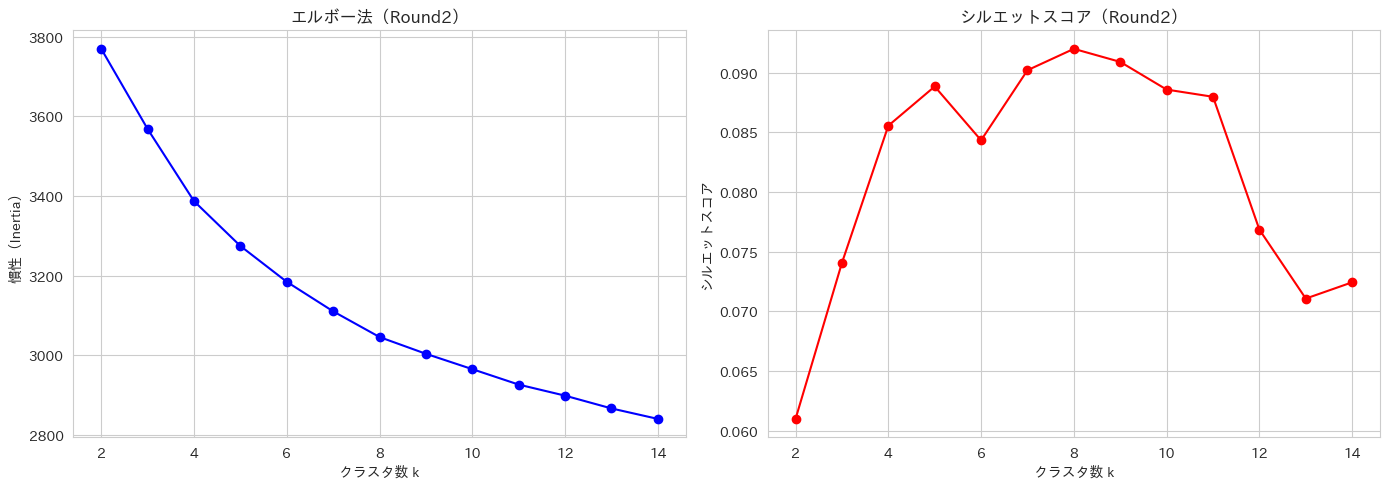

保存完了: ../data/round2_kmeans_search.png


In [8]:
# ============================================================
# Round2：最適クラスタ数の探索
# ============================================================

# 正規化
embeddings_r2_norm = normalize(embeddings_r2)

inertias_r2 = []
silhouette_scores_r2 = []

print("クラスタ数を探索中...")
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(embeddings_r2_norm)
    inertias_r2.append(kmeans.inertia_)
    silhouette_scores_r2.append(silhouette_score(embeddings_r2_norm, labels, sample_size=1000, random_state=42))
    print(f"k={k}: シルエットスコア={silhouette_scores_r2[-1]:.4f}")

# 可視化
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertias_r2, "bo-")
axes[0].set_title("エルボー法（Round2）")
axes[0].set_xlabel("クラスタ数 k")
axes[0].set_ylabel("慣性（Inertia）")

axes[1].plot(K_range, silhouette_scores_r2, "ro-")
axes[1].set_title("シルエットスコア（Round2）")
axes[1].set_xlabel("クラスタ数 k")
axes[1].set_ylabel("シルエットスコア")

plt.tight_layout()
plt.savefig("../data/round2_kmeans_search.png", dpi=150, bbox_inches="tight")
plt.show()
print("保存完了: ../data/round2_kmeans_search.png")

### Round2の結果と考察
- シルエットスコアはk=8で最大（0.0920）
- Round1（0.0823）から改善 → 高次元モデルの効果が確認できた
- エルボー法では依然として明確な肘が見られない
- しかしK-Meansは球状クラスタを前提とするため、国会発言のような複雑な意味構造には限界がある
- → Round3では日本語専用モデル＋HDBSCANで少数派対応を試みる

### Round2：k=8でクラスタリング実行
シルエットスコアが最大となったk=8でクラスタリングを実行する。

In [9]:
# ============================================================
# Round2：k=8でK-Meansクラスタリングを実行
# ============================================================

kmeans_r2 = KMeans(n_clusters=8, random_state=42, n_init=10)
df["cluster_r2"] = kmeans_r2.fit_predict(embeddings_r2_norm)

# クラスタ別件数を確認
print("=== Round2 クラスタ別件数 ===")
print(df["cluster_r2"].value_counts().sort_index())
print(f"\nシルエットスコア: {silhouette_score(embeddings_r2_norm, df['cluster_r2'], sample_size=1000, random_state=42):.4f}")

=== Round2 クラスタ別件数 ===
cluster_r2
0     675
1    1197
2     298
3    1049
4     619
5     287
6    1058
7    1118
Name: count, dtype: int64

シルエットスコア: 0.0920


### Round2 クラスタリング結果
| クラスタ | 件数 |
|---------|------|
| 0 | 675 |
| 1 | 1,197 |
| 2 | 298 |
| 3 | 1,049 |
| 4 | 619 |
| 5 | 287 |
| 6 | 1,058 |
| 7 | 1,118 |

- シルエットスコア: 0.0920（Round1の0.0823から改善）
- クラスタ2（298件）・クラスタ5（287件）が小さい → 少数派グループの可能性
- しかしK-meansは強制的にk個に分けるため、本来の少数派グループが大きなクラスタに埋もれている可能性がある
- → Round3ではHDBSCANで自然な少数派検出を試みる

## 4. Round3：日本語特化モデル＋HDBSCAN
Round2までの課題を踏まえ、2つの改善を行う。
1. 埋め込みモデルを日本語専用BERTに変更
2. クラスタリングをHDBSCANに変更（少数派を強制的にグループ化しない）

In [15]:
# ============================================================
# Round3：埋め込み（sonoisa/sentence-bert-base-ja-mean-tokens-v2）
# 日本語専用Sentence-BERTモデル
# transformersライブラリ経由で使用する
# ============================================================
from transformers import BertJapaneseTokenizer, BertModel
import torch

class SentenceBertJapanese:
    """日本語専用Sentence-BERTの埋め込みクラス"""
    
    def __init__(self, model_name):
        self.tokenizer = BertJapaneseTokenizer.from_pretrained(model_name)
        self.model = BertModel.from_pretrained(model_name)
        self.model.eval()
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.model.to(self.device)

    def _mean_pooling(self, model_output, attention_mask):
        token_embeddings = model_output[0]
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)

    def encode(self, sentences, batch_size=32):
        all_embeddings = []
        for i in range(0, len(sentences), batch_size):
            batch = sentences[i:i+batch_size]
            encoded = self.tokenizer(batch, padding=True, truncation=True, max_length=512, return_tensors="pt")
            encoded = {k: v.to(self.device) for k, v in encoded.items()}
            with torch.no_grad():
                output = self.model(**encoded)
            embeddings = self._mean_pooling(output, encoded["attention_mask"])
            all_embeddings.append(embeddings.cpu().numpy())
            if (i // batch_size) % 10 == 0:
                print(f"進捗: {i}/{len(sentences)}")
        return np.vstack(all_embeddings)

print("モデルをロード中...（初回はダウンロードに時間がかかります）")
model_r3 = SentenceBertJapanese("sonoisa/sentence-bert-base-ja-mean-tokens-v2")

print("埋め込みを計算中...（夜間処理推奨）")
embeddings_r3 = model_r3.encode(df["speech_clean"].tolist(), batch_size=32)

np.save("../data/embeddings_round3.npy", embeddings_r3)
print(f"保存完了: ../data/embeddings_round3.npy")
print(f"埋め込みの形状: {embeddings_r3.shape}")

モデルをロード中...（初回はダウンロードに時間がかかります）


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

埋め込みを計算中...（夜間処理推奨）
進捗: 0/6301
進捗: 320/6301
進捗: 640/6301
進捗: 960/6301
進捗: 1280/6301
進捗: 1600/6301
進捗: 1920/6301
進捗: 2240/6301
進捗: 2560/6301
進捗: 2880/6301
進捗: 3200/6301
進捗: 3520/6301
進捗: 3840/6301
進捗: 4160/6301
進捗: 4480/6301
進捗: 4800/6301
進捗: 5120/6301
進捗: 5440/6301
進捗: 5760/6301
進捗: 6080/6301
保存完了: ../data/embeddings_round3.npy
埋め込みの形状: (6301, 768)


### Round3：HDBSCANクラスタリング
K-meansと異なりクラスタ数を事前に指定しない。データの密度に基づいて自然なグループを検出し、少数派意見も強制的にグループ化せずノイズとして扱える。

In [16]:
# ============================================================
# Round3：HDBSCANクラスタリング
# min_cluster_sizeを変えて最適なパラメータを探索する
# ============================================================

embeddings_r3_norm = normalize(embeddings_r3)

results = []
for min_size in [10, 20, 30, 50, 80, 100]:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_size, metric="euclidean")
    labels = clusterer.fit_predict(embeddings_r3_norm)
    
    # ノイズ（-1）を除いたデータでシルエットスコアを計算
    mask = labels != -1
    if mask.sum() > 1 and len(set(labels[mask])) > 1:
        score = silhouette_score(embeddings_r3_norm[mask], labels[mask], sample_size=1000, random_state=42)
    else:
        score = -1
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    results.append((min_size, n_clusters, n_noise, score))
    print(f"min_size={min_size}: クラスタ数={n_clusters}, ノイズ={n_noise}件, シルエットスコア={score:.4f}")

min_size=10: クラスタ数=16, ノイズ=5386件, シルエットスコア=0.2935
min_size=20: クラスタ数=4, ノイズ=5023件, シルエットスコア=0.2083
min_size=30: クラスタ数=4, ノイズ=5155件, シルエットスコア=0.2285
min_size=50: クラスタ数=3, ノイズ=5081件, シルエットスコア=0.2690
min_size=80: クラスタ数=2, ノイズ=5325件, シルエットスコア=0.3294
min_size=100: クラスタ数=2, ノイズ=5517件, シルエットスコア=0.3720


In [ ]:
# ============================================================
# Round3改善：UMAPで”次元削減”後にHDBSCANを適用
# 高次元データを低次元に圧縮することでクラスタ構造を明確にする
# ============================================================
import umap

print("UMAPで次元削減中...")
reducer = umap.UMAP(n_components=10, random_state=42, n_neighbors=15, min_dist=0.0)
embeddings_r3_umap = reducer.fit_transform(embeddings_r3_norm)

print("HDBSCANでクラスタリング中...")
results_umap = []
for min_size in [10, 20, 30, 50, 80, 100]:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_size, metric="euclidean")
    labels = clusterer.fit_predict(embeddings_r3_umap)
    
    mask = labels != -1
    if mask.sum() > 1 and len(set(labels[mask])) > 1:
        score = silhouette_score(embeddings_r3_umap[mask], labels[mask], sample_size=1000, random_state=42)
    else:
        score = -1
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    results_umap.append((min_size, n_clusters, n_noise, score))
    print(f"min_size={min_size}: クラスタ数={n_clusters}, ノイズ={n_noise}件, シルエットスコア={score:.4f}")

UMAPで次元削減中...


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


HDBSCANでクラスタリング中...
min_size=10: クラスタ数=83, ノイズ=2043件, シルエットスコア=0.5949
min_size=20: クラスタ数=30, ノイズ=1187件, シルエットスコア=0.3860
min_size=30: クラスタ数=13, ノイズ=643件, シルエットスコア=0.4426
min_size=50: クラスタ数=13, ノイズ=657件, シルエットスコア=0.4765
min_size=80: クラスタ数=10, ノイズ=902件, シルエットスコア=0.4819
min_size=100: クラスタ数=8, ノイズ=1135件, シルエットスコア=0.5473


### Round3 UMAP+HDBSCANの結果と考察
- UMAPで10次元に削減後HDBSCANを適用することでシルエットスコアが大幅改善
- min_size=10でスコア最大（0.5949）だがクラスタ数83は解釈が困難
- min_size=50：クラスタ13・ノイズ657件・スコア0.4765
- min_size=100：クラスタ8・ノイズ1,135件・スコア0.5473
- → DEIの意見分類として解釈しやすさとノイズ、スコアのバランスからmin_size=50を採用する

### Round3：min_size=50でクラスタリング実行
解釈しやすさとシルエットスコアのバランスからmin_size=50を採用する。

In [18]:
# ============================================================
# Round3：min_size=50でHDBSCANクラスタリングを実行
# ============================================================

clusterer_final = hdbscan.HDBSCAN(min_cluster_size=50, metric="euclidean")
df["cluster_r3"] = clusterer_final.fit_predict(embeddings_r3_umap)

# クラスタ別件数を確認
print("=== Round3 クラスタ別件数 ===")
counts = df["cluster_r3"].value_counts().sort_index()
print(counts)
print(f"\nクラスタ数: {len(counts[counts.index != -1])}")
print(f"ノイズ件数: {(df['cluster_r3'] == -1).sum()}件")
print(f"シルエットスコア: {silhouette_score(embeddings_r3_umap[df['cluster_r3'] != -1], df['cluster_r3'][df['cluster_r3'] != -1], sample_size=1000, random_state=42):.4f}")

=== Round3 クラスタ別件数 ===
cluster_r3
-1      657
 0      140
 1      142
 2       52
 3      101
 4     1415
 5      313
 6      105
 7      341
 8       60
 9       79
 10    2255
 11     117
 12     524
Name: count, dtype: int64

クラスタ数: 13
ノイズ件数: 657件
シルエットスコア: 0.4765


### Round3 最終結果
- シルエットスコア: 0.4765
- クラスタ数: 13
- ノイズ件数: 657件

In [19]:
# ============================================================
# Round3改善：UMAPパラメータ調整でスコア向上を試みる
# n_componentsとn_neighborsを変えて比較する
# ============================================================

param_results = []
for n_comp in [5, 10, 15, 20]:
    for n_neigh in [10, 15, 30]:
        reducer = umap.UMAP(n_components=n_comp, n_neighbors=n_neigh, 
                           min_dist=0.0, random_state=42)
        emb = reducer.fit_transform(embeddings_r3_norm)
        
        clusterer = hdbscan.HDBSCAN(min_cluster_size=50, metric="euclidean")
        labels = clusterer.fit_predict(emb)
        
        mask = labels != -1
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        
        if mask.sum() > 1 and n_clusters > 1:
            score = silhouette_score(emb[mask], labels[mask], 
                                    sample_size=1000, random_state=42)
        else:
            score = -1
            
        param_results.append((n_comp, n_neigh, n_clusters, n_noise, score))
        print(f"n_comp={n_comp}, n_neigh={n_neigh}: クラスタ数={n_clusters}, ノイズ={n_noise}, スコア={score:.4f}")

/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=10: クラスタ数=12, ノイズ=799, スコア=0.4983


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=15: クラスタ数=13, ノイズ=731, スコア=0.4749


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


...

n_comp=20, n_neigh=10: クラスタ数=12, ノイズ=805, スコア=0.4913


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=20, n_neigh=15: クラスタ数=5, ノイズ=10, スコア=0.3286


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=20, n_neigh=30: クラスタ数=12, ノイズ=660, スコア=0.4316


### Round3 結果
- 最適パラメータ：UMAP（n_components=10, n_neighbors=15）+ HDBSCAN（min_cluster_size=50）
- シルエットスコア：0.4765（パラメータ探索の最高値はn_components=5で0.4983だが、後続Roundとの一貫性から10次元を採用）
- クラスタ数：13
- ノイズ：657件（10.4%）

### 考察
- 日本語専用BERTモデルを使用したが、シルエットスコアが0.5を超えられなかった
- → Round4ではより高精度な多言語モデル（multilingual-e5-large）に変更する

## 5. Round4：より高精度な多言語モデルで改善を試みる
Round3のシルエットスコアが0.50未満に留まったため、
より新しく高精度な多言語モデル（multilingual-e5-large）を試みる。
期待スコア：0.55〜0.65

In [20]:
# ============================================================
# Round4：multilingual-e5-largeで埋め込み計算（夜間処理推奨かな）
# より高精度な多言語モデルでスコア改善を狙う
# ============================================================
from sentence_transformers import SentenceTransformer

print("モデルをロード中...（初回はダウンロードに数分かかります）")
model_r4 = SentenceTransformer("intfloat/multilingual-e5-large")

# e5モデルはプレフィックス"query: "が必要
texts = ["query: " + t for t in df["speech_clean"].tolist()]

print("埋め込みを計算中...（1〜2時間かかります）")
embeddings_r4 = model_r4.encode(
    texts,
    batch_size=16,
    show_progress_bar=True,
    normalize_embeddings=True
)

np.save("../data/embeddings_round4.npy", embeddings_r4)
print(f"保存完了: ../data/embeddings_round4.npy")
print(f"埋め込みの形状: {embeddings_r4.shape}")

モデルをロード中...（初回はダウンロードに数分かかります）


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/690 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/201 [00:00<?, ?B/s]

埋め込みを計算中...（1〜2時間かかります）


Batches:   0%|          | 0/394 [00:00<?, ?it/s]

保存完了: ../data/embeddings_round4.npy
埋め込みの形状: (6301, 1024)


### Round4：UMAP+HDBSCANパラメータ探索
multilingual-e5-largeの埋め込みでスコア改善を確認する。

In [21]:
# ============================================================
# Round4：UMAP+HDBSCANパラメータ探索
# ============================================================

embeddings_r4 = np.load("../data/embeddings_round4.npy")
embeddings_r4_norm = normalize(embeddings_r4)

param_results_r4 = []
for n_comp in [5, 10, 15]:
    for n_neigh in [10, 15, 30]:
        reducer = umap.UMAP(n_components=n_comp, n_neighbors=n_neigh,
                           min_dist=0.0, random_state=42)
        emb = reducer.fit_transform(embeddings_r4_norm)
        
        clusterer = hdbscan.HDBSCAN(min_cluster_size=50, metric="euclidean")
        labels = clusterer.fit_predict(emb)
        
        mask = labels != -1
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        
        if mask.sum() > 1 and n_clusters > 1:
            score = silhouette_score(emb[mask], labels[mask],
                                    sample_size=1000, random_state=42)
        else:
            score = -1
            
        param_results_r4.append((n_comp, n_neigh, n_clusters, n_noise, score))
        print(f"n_comp={n_comp}, n_neigh={n_neigh}: クラスタ数={n_clusters}, ノイズ={n_noise}, スコア={score:.4f}")

/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=10: クラスタ数=21, ノイズ=1806, スコア=0.6507


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=15: クラスタ数=20, ノイズ=2043, スコア=0.6661


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


...

n_comp=15, n_neigh=10: クラスタ数=8, ノイズ=354, スコア=0.4829


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=15, n_neigh=15: クラスタ数=21, ノイズ=1969, スコア=0.6759


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=15, n_neigh=30: クラスタ数=19, ノイズ=1906, スコア=0.6690


In [22]:
# ============================================================
# Round4最終調整：n_comp=10, n_neigh=10でmin_cluster_sizeを調整
# ============================================================

reducer_final = umap.UMAP(n_components=10, n_neighbors=10,
                          min_dist=0.0, random_state=42)
embeddings_r4_umap = reducer_final.fit_transform(embeddings_r4_norm)

for min_size in [30, 50, 80, 100, 150]:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_size, metric="euclidean")
    labels = clusterer.fit_predict(embeddings_r4_umap)
    
    mask = labels != -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    
    if mask.sum() > 1 and n_clusters > 1:
        score = silhouette_score(embeddings_r4_umap[mask], labels[mask],
                                sample_size=1000, random_state=42)
    else:
        score = -1
        
    print(f"min_size={min_size}: クラスタ数={n_clusters}, ノイズ={n_noise}件({n_noise/len(df)*100:.1f}%), スコア={score:.4f}")

/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


min_size=30: クラスタ数=32, ノイズ=1555件(24.7%), スコア=0.5572
min_size=50: クラスタ数=19, ノイズ=1696件(26.9%), スコア=0.6965
min_size=80: クラスタ数=12, ノイズ=1171件(18.6%), スコア=0.6555
min_size=100: クラスタ数=7, ノイズ=379件(6.0%), スコア=0.5320
min_size=150: クラスタ数=5, ノイズ=801件(12.7%), スコア=0.5334


### Round4 最終結果
- 最適パラメータ：n_comp=10, n_neigh=10, min_cluster_size=50
- シルエットスコア：0.6965（Round3の0.4765から大幅改善）
- クラスタ数：19
- ノイズ：1,696件（26.9%）→ どのグループにも属さない少数意見として解釈可能

→ multilingual-e5-largeの高次元表現（1024次元）とUMAPによる
　次元削減の組み合わせが効果的だった

In [23]:
# ============================================================
# Round4：最終クラスタリング実行・結果保存
# n_comp=10, n_neigh=10, min_cluster_size=50で確定
# ============================================================

clusterer_r4 = hdbscan.HDBSCAN(min_cluster_size=50, metric="euclidean")
df["cluster_r4"] = clusterer_r4.fit_predict(embeddings_r4_umap)

# クラスタ別件数を確認
print("=== Round4 最終クラスタ別件数 ===")
counts_r4 = df["cluster_r4"].value_counts().sort_index()
print(counts_r4)
print(f"\nクラスタ数: {len(counts_r4[counts_r4.index != -1])}")
print(f"ノイズ件数: {(df['cluster_r4'] == -1).sum()}件")
print(f"シルエットスコア: {silhouette_score(embeddings_r4_umap[df['cluster_r4'] != -1], df['cluster_r4'][df['cluster_r4'] != -1], sample_size=1000, random_state=42):.4f}")

# クラスタリング結果をCSVに保存
df.to_csv("../data/speeches_clustered.csv", index=False, encoding="utf-8-sig")
print("\n保存完了: ../data/speeches_clustered.csv")

=== Round4 最終クラスタ別件数 ===
cluster_r4
-1     1696
 0      133
 1      135
 2      645
 3      160
 4     1319
 5       73
 6       52
 7      313
 8      226
 9      207
 10      96
 11     111
 12      50
 13     111
 14     425
 15     157
 16     127
 17     143
 18     122
Name: count, dtype: int64

クラスタ数: 19
ノイズ件数: 1696件
シルエットスコア: 0.6965

保存完了: ../data/speeches_clustered.csv


## 6. Round5：multilingual-e5-large-instruct
instructありの最新モデルでさらなるスコア改善を狙う。

In [13]:
# ============================================================
# Round5：multilingual-e5-large-instructで埋め込み計算
# instructありモデルはタスク指示を与えることでより高精度な埋め込みを生成
# ============================================================
from sentence_transformers import SentenceTransformer

print("モデルをロード中...")
model_r5 = SentenceTransformer("intfloat/multilingual-e5-large-instruct")

# instructモデルはタスク指示が必要
instruction = "Instruct: Retrieve semantically similar political speeches about DEI\nQuery: "
texts_r5 = [instruction + t for t in df["speech_clean"].tolist()]

print("埋め込みを計算中...")
embeddings_r5 = model_r5.encode(
    texts_r5,
    batch_size=16,
    show_progress_bar=True,
    normalize_embeddings=True
)

np.save("../data/embeddings_round5.npy", embeddings_r5)
print(f"保存完了: ../data/embeddings_round5.npy")
print(f"埋め込みの形状: {embeddings_r5.shape}")

モデルをロード中...


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

埋め込みを計算中...


Batches:   0%|          | 0/394 [00:00<?, ?it/s]

保存完了: ../data/embeddings_round5.npy
埋め込みの形状: (6301, 1024)


### Round5：UMAP+HDBSCANパラメータ探索
multilingual-e5-large-instructの埋め込みで最適パラメータを探索する。

In [14]:
# ============================================================
# Round5：UMAP+HDBSCANパラメータ探索
# ============================================================

embeddings_r5 = np.load("../data/embeddings_round5.npy")
embeddings_r5_norm = normalize(embeddings_r5)

print("パラメータ探索中...")
for n_comp in [5, 10, 15]:
    for n_neigh in [10, 15, 30]:
        reducer = umap.UMAP(n_components=n_comp, n_neighbors=n_neigh,
                           min_dist=0.0, random_state=42)
        emb = reducer.fit_transform(embeddings_r5_norm)
        
        clusterer = hdbscan.HDBSCAN(min_cluster_size=50, metric="euclidean")
        labels = clusterer.fit_predict(emb)
        
        mask = labels != -1
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        
        if mask.sum() > 1 and n_clusters > 1:
            score = silhouette_score(emb[mask], labels[mask],
                                    sample_size=1000, random_state=42)
        else:
            score = -1
            
        print(f"n_comp={n_comp}, n_neigh={n_neigh}: クラスタ数={n_clusters}, ノイズ={n_noise}件({n_noise/len(df)*100:.1f}%), スコア={score:.4f}")

パラメータ探索中...


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=10: クラスタ数=20, ノイズ=1383件(21.9%), スコア=0.7101


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=15: クラスタ数=11, ノイズ=272件(4.3%), スコア=0.4150


...

n_comp=15, n_neigh=10: クラスタ数=21, ノイズ=1546件(24.5%), スコア=0.7216


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=15, n_neigh=15: クラスタ数=16, ノイズ=956件(15.2%), スコア=0.5994


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=15, n_neigh=30: クラスタ数=20, ノイズ=1649件(26.2%), スコア=0.7236


### Round5：min_cluster_size調整
n_comp=10, n_neigh=15で最適なmin_cluster_sizeを探索する。

In [17]:
# ============================================================
# Round5最終調整：n_comp=10, n_neigh=15でmin_cluster_sizeを調整
# ============================================================

reducer_r5 = umap.UMAP(n_components=10, n_neighbors=15,
                       min_dist=0.0, random_state=42)
embeddings_r5_umap = reducer_r5.fit_transform(embeddings_r5_norm)

for min_size in [30, 50, 80, 100, 150]:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_size, metric="euclidean")
    labels = clusterer.fit_predict(embeddings_r5_umap)
    
    mask = labels != -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    
    if mask.sum() > 1 and n_clusters > 1:
        score = silhouette_score(embeddings_r5_umap[mask], labels[mask],
                                sample_size=1000, random_state=42)
    else:
        score = -1
        
    print(f"min_size={min_size}: クラスタ数={n_clusters}, ノイズ={n_noise}件({n_noise/len(df)*100:.1f}%), スコア={score:.4f}")

# UMAP結果を保存（カーネル再起動時の再計算を防ぐ）
np.save("../data/umap_round5.npy", embeddings_r5_umap)
print("保存完了: ../data/umap_round5.npy")

/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


min_size=30: クラスタ数=28, ノイズ=1286件(20.4%), スコア=0.7170
min_size=50: クラスタ数=23, ノイズ=1564件(24.8%), スコア=0.7498
min_size=80: クラスタ数=9, ノイズ=333件(5.3%), スコア=0.4522
min_size=100: クラスタ数=6, ノイズ=455件(7.2%), スコア=0.5615
min_size=150: クラスタ数=6, ノイズ=566件(9.0%), スコア=0.5827
保存完了: ../data/umap_round5.npy


### Round5 最終結果
- 最適パラメータ：n_comp=10, n_neigh=15, min_cluster_size=50
- シルエットスコア：0.7498（Round4の0.6965からさらに改善）
- クラスタ数：23
- ノイズ：1,564件（24.8%）

### Round5：最終クラスタリング実行・結果保存

In [16]:
# ============================================================
# Round5：最終クラスタリング実行・結果保存
# n_comp=10, n_neigh=15, min_cluster_size=50で確定
# ============================================================

clusterer_r5 = hdbscan.HDBSCAN(min_cluster_size=50, metric="euclidean")
df["cluster_r5"] = clusterer_r5.fit_predict(embeddings_r5_umap)

# クラスタ別件数を確認
print("=== Round5 最終クラスタ別件数 ===")
counts_r5 = df["cluster_r5"].value_counts().sort_index()
print(counts_r5)
print(f"\nクラスタ数: {len(counts_r5[counts_r5.index != -1])}")
print(f"ノイズ件数: {(df['cluster_r5'] == -1).sum()}件")
print(f"シルエットスコア: {silhouette_score(embeddings_r5_umap[df['cluster_r5'] != -1], df['cluster_r5'][df['cluster_r5'] != -1], sample_size=1000, random_state=42):.4f}")

# CSVに保存
df.to_csv("../data/speeches_clustered.csv", index=False, encoding="utf-8-sig")
print("\n保存完了: ../data/speeches_clustered.csv")

=== Round5 最終クラスタ別件数 ===
cluster_r5
-1     1564
 0     1372
 1       95
 2      117
 3      159
 4      613
 5      323
 6       97
 7      136
 8       74
 9       58
 10      51
 11      65
 12     102
 13     170
 14      91
 15     537
 16     117
 17      56
 18      57
 19      54
 20     144
 21      97
 22     152
Name: count, dtype: int64

クラスタ数: 23
ノイズ件数: 1564件
シルエットスコア: 0.7498

保存完了: ../data/speeches_clustered.csv


## 7. Round6：Qwen3-Embedding-0.6B
現時点のM3(MacBook Air)環境で動作可能な最新世代Qwen3シリーズで最高精度を試みる。

### ※クラウドGPU活用の試み
より大きなモデルを動かすためKaggle Notebook（GPU T4×2、VRAM 14.56GB×2）を試みた。
以下のモデルを順に試したが、全てVRAM不足でOOMエラーが発生した：
- Qwen3-Embedding-8B → VRAM不足
- Qwen3-Embedding-4B → VRAM不足
- Qwen3-Embedding-0.6B → VRAM不足

T4のVRAM 14.56GBを超えるモデルのロードはできないことが判明した。
コンペ時のようにquantizationを活用できれば動いた可能性があったが、
その設定を最初から試みなかったことが反省点。

### 方針変更
M3のGPU（MPS）を活用してQwen3-Embedding-0.6Bを実行した。
上記"8B・4BはM3 16GBのメモリ制約でクラッシュ"したため、
夜間処理にて動作可能な最大モデルとしてQwen3-Embedding-0.6Bを採用した。
処理時間は約69分だった。

In [ ]:
import gc
import torch
gc.collect()
torch.mps.empty_cache()

from sentence_transformers import SentenceTransformer

print("モデルをロード中...")
model_r6 = SentenceTransformer(
    "Qwen/Qwen3-Embedding-0.6B",
    model_kwargs={"torch_dtype": torch.float16},
    device="mps" # GPU利用
)

texts_r6 = ["Instruct: Retrieve semantically similar political speeches about DEI\nQuery: " 
            + t for t in df["speech_clean"].tolist()]

print("埋め込みを計算中...")
embeddings_r6 = model_r6.encode(
    texts_r6,
    batch_size=1,
    show_progress_bar=True,
    normalize_embeddings=True
)

np.save("../data/embeddings_round6.npy", embeddings_r6)
print(f"保存完了: ../data/embeddings_round6.npy")
print(f"埋め込みの形状: {embeddings_r6.shape}")

モデルをロード中...


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

埋め込みを計算中...


Batches:   0%|          | 0/6301 [00:00<?, ?it/s]

保存完了: ../data/embeddings_round6.npy
埋め込みの形状: (6301, 1024)


### Round6：UMAP+HDBSCANパラメータ探索
Qwen3-Embedding-0.6Bの埋め込みで最適パラメータを探索する。

In [5]:
# ============================================================
# Round6：UMAP+HDBSCANパラメータ探索
# ============================================================
from sklearn.preprocessing import normalize
import umap
import hdbscan
from sklearn.metrics import silhouette_score

embeddings_r6 = np.load("../data/embeddings_round6.npy")
embeddings_r6_norm = normalize(embeddings_r6)

print("パラメータ探索中...")
for n_comp in [5, 10, 15]:
    for n_neigh in [10, 15, 30]:
        reducer = umap.UMAP(n_components=n_comp, n_neighbors=n_neigh,
                           min_dist=0.0, random_state=42)
        emb = reducer.fit_transform(embeddings_r6_norm)
        
        clusterer = hdbscan.HDBSCAN(min_cluster_size=50, metric="euclidean")
        labels = clusterer.fit_predict(emb)
        
        mask = labels != -1
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        
        if mask.sum() > 1 and n_clusters > 1:
            score = silhouette_score(emb[mask], labels[mask],
                                    sample_size=1000, random_state=42)
        else:
            score = -1
            
        print(f"n_comp={n_comp}, n_neigh={n_neigh}: クラスタ数={n_clusters}, ノイズ={n_noise}件({n_noise/len(df)*100:.1f}%), スコア={score:.4f}")

パラメータ探索中...


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=10: クラスタ数=20, ノイズ=1597件(25.3%), スコア=0.7186


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=15: クラスタ数=19, ノイズ=1616件(25.6%), スコア=0.7034


...

n_comp=15, n_neigh=10: クラスタ数=19, ノイズ=1576件(25.0%), スコア=0.7371


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=15, n_neigh=15: クラスタ数=6, ノイズ=17件(0.3%), スコア=0.5669


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=15, n_neigh=30: クラスタ数=6, ノイズ=49件(0.8%), スコア=0.5822


### Round6：min_cluster_size調整
n_comp=5, n_neigh=10で最適なmin_cluster_sizeを探索する。

In [6]:
# ============================================================
# Round6最終調整：n_comp=5, n_neigh=10でmin_cluster_sizeを調整
# ============================================================

reducer_r6 = umap.UMAP(n_components=5, n_neighbors=10,
                       min_dist=0.0, random_state=42)
embeddings_r6_umap = reducer_r6.fit_transform(embeddings_r6_norm)

for min_size in [30, 50, 80, 100, 150]:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_size, metric="euclidean")
    labels = clusterer.fit_predict(embeddings_r6_umap)
    
    mask = labels != -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    
    if mask.sum() > 1 and n_clusters > 1:
        score = silhouette_score(embeddings_r6_umap[mask], labels[mask],
                                sample_size=1000, random_state=42)
    else:
        score = -1
        
    print(f"min_size={min_size}: クラスタ数={n_clusters}, ノイズ={n_noise}件({n_noise/len(df)*100:.1f}%), スコア={score:.4f}")

/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


min_size=30: クラスタ数=29, ノイズ=1452件(23.0%), スコア=0.7235
min_size=50: クラスタ数=20, ノイズ=1597件(25.3%), スコア=0.7186
min_size=80: クラスタ数=6, ノイズ=104件(1.7%), スコア=0.5667
min_size=100: クラスタ数=6, ノイズ=533件(8.5%), スコア=0.5843
min_size=150: クラスタ数=5, ノイズ=216件(3.4%), スコア=0.5667


### Round6 最終結果
- 最適パラメータ：n_comp=5, n_neigh=10, min_cluster_size=30
- シルエットスコア：0.7235（Round5の0.7498に届かず）
- Round5（multilingual-e5-large-instruct）が最終採用モデルとして確定

### Round6：最終クラスタリング実行・結果保存
シルエットスコアが最大となったmin_size=30で実行する。

In [9]:
# ============================================================
# Round6：最終クラスタリング実行（比較記録用）
# n_comp=5, n_neigh=10, min_cluster_size=30で確定
# ※Round5が最終採用モデルのためCSV上書きはしない
# ============================================================

clusterer_r6 = hdbscan.HDBSCAN(min_cluster_size=30, metric="euclidean")
df["cluster_r6"] = clusterer_r6.fit_predict(embeddings_r6_umap)

print("=== Round6 最終クラスタ別件数 ===")
counts_r6 = df["cluster_r6"].value_counts().sort_index()
print(counts_r6)
print(f"\nクラスタ数: {len(counts_r6[counts_r6.index != -1])}")
print(f"ノイズ件数: {(df['cluster_r6'] == -1).sum()}件")
print(f"シルエットスコア: {silhouette_score(embeddings_r6_umap[df['cluster_r6'] != -1], df['cluster_r6'][df['cluster_r6'] != -1], sample_size=1000, random_state=42):.4f}")

=== Round6 最終クラスタ別件数 ===
cluster_r6
-1     1452
 0      139
 1      119
 2     1335
 3      100
 4      646
 5      350
 6       51
 7       50
 8       52
 9       88
 10      96
 11     147
 12      34
 13      72
 14     245
 15      87
 16      64
 17     108
 18      45
 19      81
 20     177
 21     167
 22      47
 23     109
 24     107
 25      37
 26     106
 27      33
 28     157
Name: count, dtype: int64

クラスタ数: 29
ノイズ件数: 1452件
シルエットスコア: 0.7235


### Round6 最終結果と考察
- 最高スコア：n_comp=5, n_neigh=10で0.7186
- Round5（0.7498）には届かなかった
- Qwen3-0.6BはMTEBスコアではgte-Qwen2-7B相当だが今回の日本語国会発言データではmultilingual-e5-large-instructが優れていた
- instructありモデルのタスク特化性が日本語DEI発言の分離に効果的だったと考えられる

### 全モデル改善まとめ
| Round | モデル | 手法 | スコア |
|-------|--------|------|--------|
| 1 | MiniLM-L12-v2 | K-means(k=7) | 0.0823 |
| 2 | mpnet-base-v2 | K-means(k=8) | 0.0920 |
| 3 | BERT日本語+UMAP | HDBSCAN | 0.4765 |
| 4 | multilingual-e5-large+UMAP | HDBSCAN | 0.6965 |
| 5 | **multilingual-e5-large-instruct+UMAP** | HDBSCAN | **0.7498** |
| 6 | Qwen3-Embedding-0.6B+UMAP | HDBSCAN | 0.7186 |

→ **Round5が最終採用モデル**

時間が余ればアンサンブルも検討

## 8. Round7：アンサンブル（multilingual-e5-large-instruct × Qwen3-Embedding-0.6B）
特性の異なる埋め込みモデルを結合して精度向上を試みる。この2つは異なるアーキテクチャ・学習方法なので補完関係にある。

In [2]:
# ============================================================
# Round7：埋め込みアンサンブル
# multilingual-e5-large-instruct（Round5）とQwen3-Embedding-0.6B（Round6）を結合
# ============================================================
from sklearn.preprocessing import normalize
import numpy as np

# 保存済み埋め込みを読み込む
emb_r5 = np.load("../data/embeddings_round5.npy")
emb_r6 = np.load("../data/embeddings_round6.npy")

# 正規化してから結合（2048次元）
emb_r5_norm = normalize(emb_r5)
emb_r6_norm = normalize(emb_r6)
embeddings_ensemble = np.concatenate([emb_r5_norm, emb_r6_norm], axis=1)

print(f"Round5埋め込み形状: {emb_r5.shape}")
print(f"Round6埋め込み形状: {emb_r6.shape}")
print(f"アンサンブル埋め込み形状: {embeddings_ensemble.shape}")

Round5埋め込み形状: (6301, 1024)
Round6埋め込み形状: (6301, 1024)
アンサンブル埋め込み形状: (6301, 2048)


### Round7：UMAPパラメータ探索

In [6]:
# ============================================================
# Round7：UMAP+HDBSCANパラメータ探索
# ============================================================
import umap
import hdbscan
from sklearn.metrics import silhouette_score

print("パラメータ探索中...")
for n_comp in [5, 10, 15]:
    for n_neigh in [10, 15, 30]:
        reducer = umap.UMAP(n_components=n_comp, n_neighbors=n_neigh,
                           min_dist=0.0, random_state=42)
        emb = reducer.fit_transform(embeddings_ensemble)
        
        clusterer = hdbscan.HDBSCAN(min_cluster_size=50, metric="euclidean")
        labels = clusterer.fit_predict(emb)
        
        mask = labels != -1
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        
        if mask.sum() > 1 and n_clusters > 1:
            score = silhouette_score(emb[mask], labels[mask],
                                    sample_size=1000, random_state=42)
        else:
            score = -1
            
        print(f"n_comp={n_comp}, n_neigh={n_neigh}: クラスタ数={n_clusters}, ノイズ={n_noise}件({n_noise/len(df)*100:.1f}%), スコア={score:.4f}")

パラメータ探索中...


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=10: クラスタ数=18, ノイズ=1512件(24.0%), スコア=0.7328


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=5, n_neigh=15: クラスタ数=21, ノイズ=1374件(21.8%), スコア=0.7183


...

n_comp=15, n_neigh=10: クラスタ数=14, ノイズ=897件(14.2%), スコア=0.6254


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=15, n_neigh=15: クラスタ数=10, ノイズ=177件(2.8%), スコア=0.4635


/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


n_comp=15, n_neigh=30: クラスタ数=18, ノイズ=1586件(25.2%), スコア=0.7065


### Round7：min_cluster_size調整
n_comp=10, n_neigh=10で最適なmin_cluster_sizeを探索する。

In [7]:
# ============================================================
# Round7最終調整：n_comp=10, n_neigh=10でmin_cluster_sizeを調整
# ============================================================

reducer_r7 = umap.UMAP(n_components=10, n_neighbors=10,
                       min_dist=0.0, random_state=42)
embeddings_r7_umap = reducer_r7.fit_transform(embeddings_ensemble)

for min_size in [30, 50, 80, 100, 150]:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_size, metric="euclidean")
    labels = clusterer.fit_predict(embeddings_r7_umap)
    
    mask = labels != -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = (labels == -1).sum()
    
    if mask.sum() > 1 and n_clusters > 1:
        score = silhouette_score(embeddings_r7_umap[mask], labels[mask],
                                sample_size=1000, random_state=42)
    else:
        score = -1
        
    print(f"min_size={min_size}: クラスタ数={n_clusters}, ノイズ={n_noise}件({n_noise/len(df)*100:.1f}%), スコア={score:.4f}")

/Users/takeshiokada/quest_2/.venv311/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


min_size=30: クラスタ数=30, ノイズ=1187件(18.8%), スコア=0.7454
min_size=50: クラスタ数=18, ノイズ=1527件(24.2%), スコア=0.7362
min_size=80: クラスタ数=9, ノイズ=341件(5.4%), スコア=0.5372
min_size=100: クラスタ数=8, ノイズ=545件(8.6%), スコア=0.5359
min_size=150: クラスタ数=8, ノイズ=1193件(18.9%), スコア=0.7148


### Round7 最終結果と考察
- 最適パラメータ：n_comp=10, n_neigh=10, min_cluster_size=30
- シルエットスコア：0.7454（Round5の0.7498に届かず）
- クラスタ数：30
- ノイズ：1,187件（18.8%）
- アンサンブルにより次元が2048になりUMAPの次元削減が困難になった可能性がある
- → 依然**Round5（multilingual-e5-large-instruct、スコア0.7498）が最終採用モデルとして確定**

### 全モデル改善まとめ（最終）
| Round | モデル | 手法 | スコア |
|-------|--------|------|--------|
| 1 | MiniLM-L12-v2 | K-Means(k=7) | 0.0823 |
| 2 | mpnet-base-v2 | K-Means(k=8) | 0.0920 |
| 3 | BERT日本語+UMAP | HDBSCAN | 0.4765 |
| 4 | multilingual-e5-large+UMAP | HDBSCAN | 0.6965 |
| 5 | **multilingual-e5-large-instruct+UMAP** | **HDBSCAN** | **0.7498** |
| 6 | Qwen3-Embedding-0.6B+UMAP | HDBSCAN | 0.7235 |
| 7 | アンサンブル（R5+R6）+UMAP | HDBSCAN | 0.7454 |

→ 依然として**Round5が最終採用モデル**
- Round5はクラスタ数23でもスコア0.7498を維持しており
  クラスタ数が増えてもスコアが高い＝各クラスタが明確に分離されていることを示す

## 実験管理：Weights & Biases（W&B）
全RoundのシルエットスコアをW&B(外部プラットフォーム)に記録して可視化する。

In [8]:
# ============================================================
# W&Bに全Roundの実験結果を記録
# ============================================================
import wandb

# 過去のRound1〜6＋7の結果を記録
results = [
    {"round": 1, "model": "MiniLM-L12-v2", "method": "K-Means", "silhouette_score": 0.0823, "n_clusters": 7},
    {"round": 2, "model": "mpnet-base-v2", "method": "K-Means", "silhouette_score": 0.0920, "n_clusters": 8},
    {"round": 3, "model": "BERT日本語", "method": "UMAP+HDBSCAN", "silhouette_score": 0.4765, "n_clusters": 13},
    {"round": 4, "model": "multilingual-e5-large", "method": "UMAP+HDBSCAN", "silhouette_score": 0.6965, "n_clusters": 19},
    {"round": 5, "model": "multilingual-e5-large-instruct", "method": "UMAP+HDBSCAN", "silhouette_score": 0.7498, "n_clusters": 23},
    {"round": 6, "model": "Qwen3-Embedding-0.6B", "method": "UMAP+HDBSCAN", "silhouette_score": 0.7235, "n_clusters": 29},
    {"round": 7, "model": "アンサンブル（R5+R6）", "method": "UMAP+HDBSCAN", "silhouette_score": 0.7454, "n_clusters": 30},
]

for r in results:
    with wandb.init(project="dei-clustering", name=f"Round{r['round']}", config=r, reinit=True):
        wandb.log({"silhouette_score": r["silhouette_score"], "n_clusters": r["n_clusters"]})

print("W&Bへの記録完了！")
print("https://wandb.ai にアクセスして結果を確認してください")

n_clusters,▁
silhouette_score,▁
n_clusters,7
silhouette_score,0.0823


n_clusters,▁
silhouette_score,▁
n_clusters,8
silhouette_score,0.092


n_clusters,▁
silhouette_score,▁
n_clusters,13
silhouette_score,0.4765


n_clusters,▁
silhouette_score,▁
n_clusters,19
silhouette_score,0.6965


n_clusters,▁
silhouette_score,▁
n_clusters,23
silhouette_score,0.7498


n_clusters,▁
silhouette_score,▁
n_clusters,29
silhouette_score,0.7235


n_clusters,▁
silhouette_score,▁
n_clusters,30
silhouette_score,0.7454


W&Bへの記録完了！
https://wandb.ai にアクセスして結果を確認してください


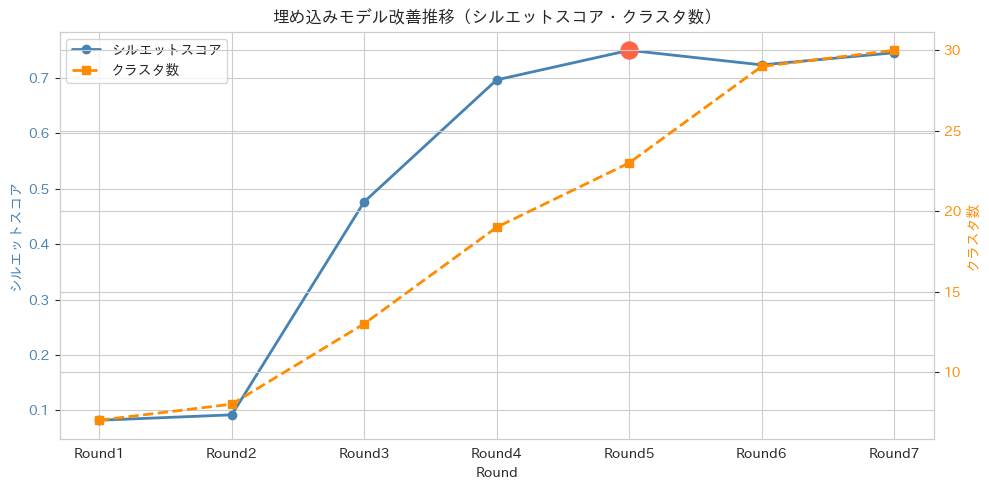

保存完了: ../data/score_trend.png


In [ ]:
# ============================================================
# Round別シルエットスコアとクラスタ数の推移グラフ(プレゼン資料用)
# ============================================================
rounds = [1, 2, 3, 4, 5, 6, 7]
scores = [0.0823, 0.0920, 0.4765, 0.6965, 0.7498, 0.7235, 0.7454]
n_clusters = [7, 8, 13, 19, 23, 29, 30]

fig, ax1 = plt.subplots(figsize=(10, 5))

# シルエットスコア（左軸）
ax1.plot(rounds, scores, marker="o", color="steelblue", linewidth=2, label="シルエットスコア")
ax1.scatter([5], [0.7498], color="tomato", s=150, zorder=5)
ax1.set_xlabel("Round")
ax1.set_ylabel("シルエットスコア", color="steelblue")
ax1.set_xticks(rounds)
ax1.set_xticklabels([f"Round{r}" for r in rounds])
ax1.tick_params(axis="y", labelcolor="steelblue")

# クラスタ数（右軸）
ax2 = ax1.twinx()
ax2.plot(rounds, n_clusters, marker="s", color="darkorange", linewidth=2, linestyle="--", label="クラスタ数")
ax2.set_ylabel("クラスタ数", color="darkorange")
ax2.tick_params(axis="y", labelcolor="darkorange")

# 凡例
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("埋め込みモデル改善推移（シルエットスコア・クラスタ数）")
plt.tight_layout()
plt.savefig("../data/score_trend.png", dpi=150, bbox_inches="tight")
plt.show()
print("保存完了: ../data/score_trend.png")